In [35]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 3.2 MB/s  0:00:03 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 3.0 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 2.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 3.0 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [36]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('../data/cleaned/cleaned_data.csv', low_memory=False, parse_dates=['release_date'])

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1505918 entries, 0 to 1505917
Data columns (total 24 columns):
 #   Column                Non-Null Count    Dtype         
---  ------                --------------    -----         
 0   id                    1505918 non-null  int64         
 1   title                 1505898 non-null  str           
 2   vote_average          360884 non-null   float64       
 3   vote_count            1505918 non-null  int64         
 4   status                1505918 non-null  str           
 5   release_date          1148261 non-null  datetime64[us]
 6   revenue               25469 non-null    float64       
 7   runtime               1027712 non-null  float64       
 8   adult                 1505918 non-null  bool          
 9   backdrop_path         366548 non-null   str           
 10  budget                88501 non-null    float64       
 11  homepage              153860 non-null   str           
 12  imdb_id               684620 non-null   str          

In [8]:
df.shape

(1505918, 24)

In [10]:
df['release_date'].dtype

dtype('<M8[us]')

In [11]:
df['id'].is_unique

True

In [37]:
release_years_count = df['release_date'].dt.year.value_counts().sort_index()

In [38]:
release_years_count

release_date
1800.0    4
1837.0    1
1865.0    4
1867.0    2
1873.0    1
         ..
2069.0    1
2074.0    1
2077.0    1
2085.0    1
2099.0    3
Name: count, Length: 186, dtype: int64

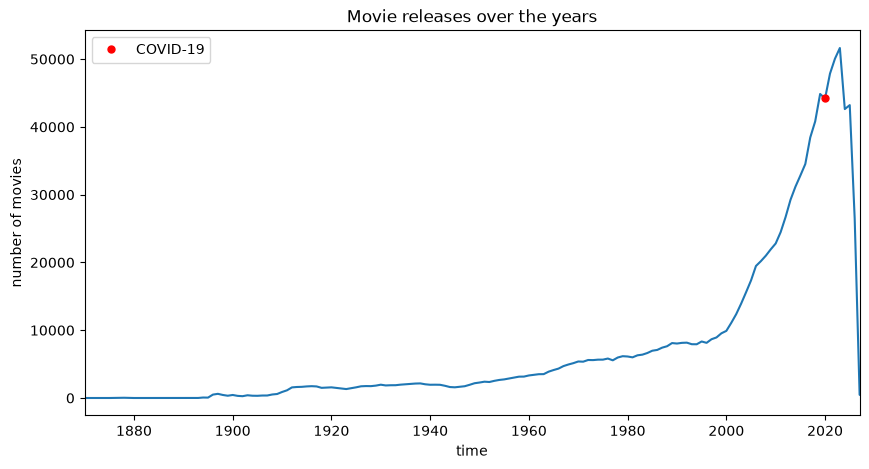

In [126]:
plt.figure(figsize=(10, 5))
plt.plot(release_years_count.index, release_years_count.values)
plt.plot(2020, release_years_count.loc[2020], 'ro', markersize=5, label='COVID-19')
plt.title('Movie releases over the years')
plt.xlabel('time')
plt.ylabel('number of movies')
plt.legend()
plt.xlim(1870, 2027)
plt.show()

## Release dates
Over time, the number of movies released per year have increased, especially since the 2000s. There is a decline in 2020 (Covid) and in 2024 and 2025 (possibly due to the 2023 Hollywood labor disputes). However, missing TMDB data might also be responsible for the declines in data. The data for 2026 is not complete at the time of writing.

In [88]:
top5_languages = df['original_language'].value_counts().head().index

In [89]:
top5_languages

Index(['en', 'fr', 'es', 'ja', 'de'], dtype='str', name='original_language')

In [92]:
language_df = df[df['original_language'].isin(top5_languages)].copy() # copy containing only our top 5 languages

In [91]:
language_df

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,8.255328e+08,148.0,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.9520,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,7.017292e+08,169.0,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.2410,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1.004558e+09,152.0,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.6430,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2.923706e+09,162.0,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.9320,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1.518816e+09,143.0,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.0820,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1505913,931166,NaN,NaN,0,Released,NaT,NaN,NaN,False,NaN,...,NaN,NaN,0.6000,NaN,NaN,Documentary,NaN,NaN,NaN,NaN
1505914,1328667,NaN,NaN,0,Released,NaT,NaN,NaN,False,NaN,...,NaN,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1505915,1582071,NaN,NaN,0,Canceled,NaT,NaN,NaN,False,NaN,...,NaN,NaN,0.0071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1505916,1548662,NaN,NaN,0,Post Production,NaT,NaN,NaN,False,NaN,...,NaN,NaN,0.0071,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [93]:
language_df['release_year'] = language_df['release_date'].dt.year

In [132]:
year_languages = language_df.groupby(['release_year', 'original_language']).size().unstack(fill_value=0)

In [142]:
year_languages.iloc[140:145]

original_language,de,en,es,fr,ja
release_year,,,,,
2016.0,1382,18847,1819,2003,2020
2017.0,1491,20617,1911,2285,2275
2018.0,1588,21190,2173,2563,2155
2019.0,1711,23278,2530,3002,2405
2020.0,1523,23365,2733,2649,2410


In [145]:
language_colors = {'en': 'red','fr': 'purple','es': 'orange','de': 'green','ja': 'blue'}

In [150]:
language_order = year_languages.sum().sort_values(ascending=False).index

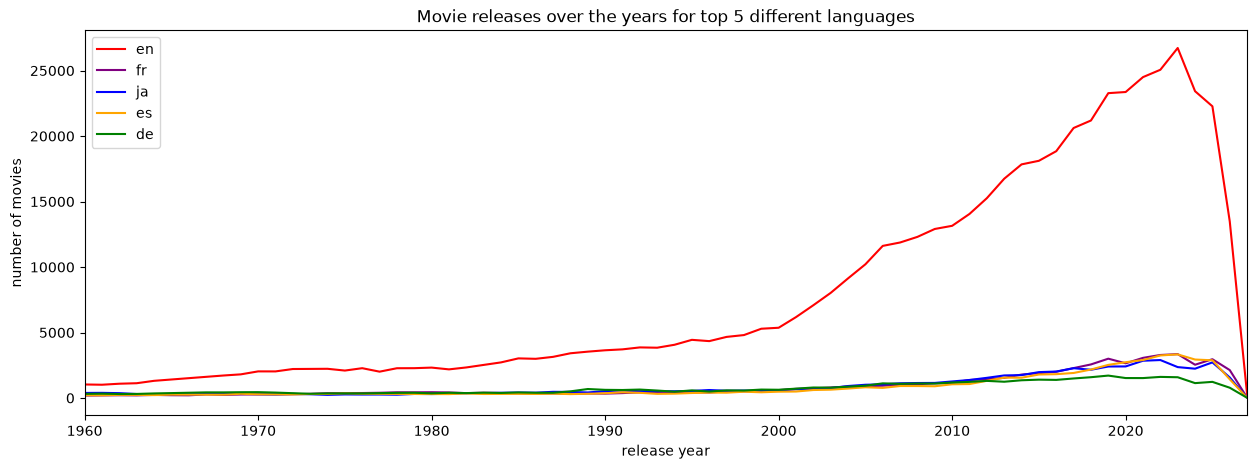

In [159]:
plt.figure(figsize=(15, 5))
for language in language_order:
    plt.plot(year_languages.index, year_languages[language], color=language_colors.get(language, 'gray'), label=language)
plt.title('Movie releases over the years for top 5 different languages')
plt.xlabel('release year')
plt.ylabel('number of movies')
plt.legend()
#plt.yscale('log')
plt.xlim(1960, 2027)
plt.show()

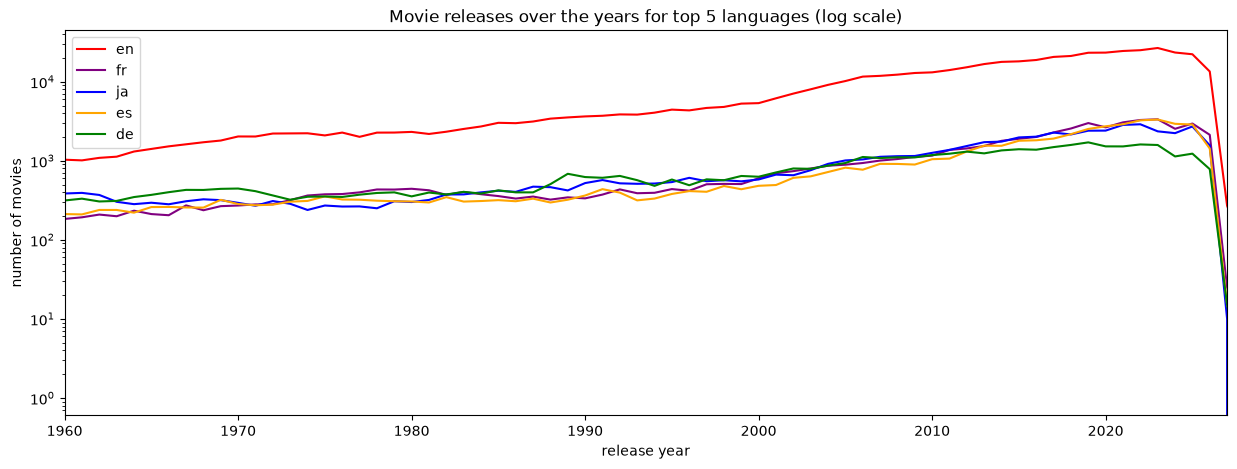

In [160]:
plt.figure(figsize=(15, 5))
for language in language_order:
    plt.plot(year_languages.index, year_languages[language], color=language_colors.get(language, 'gray'), label=language)
plt.title('Movie releases over the years for top 5 languages (log scale)')
plt.xlabel('release year')
plt.ylabel('number of movies')
plt.legend()
plt.yscale('log')
plt.xlim(1960, 2027)
plt.show()

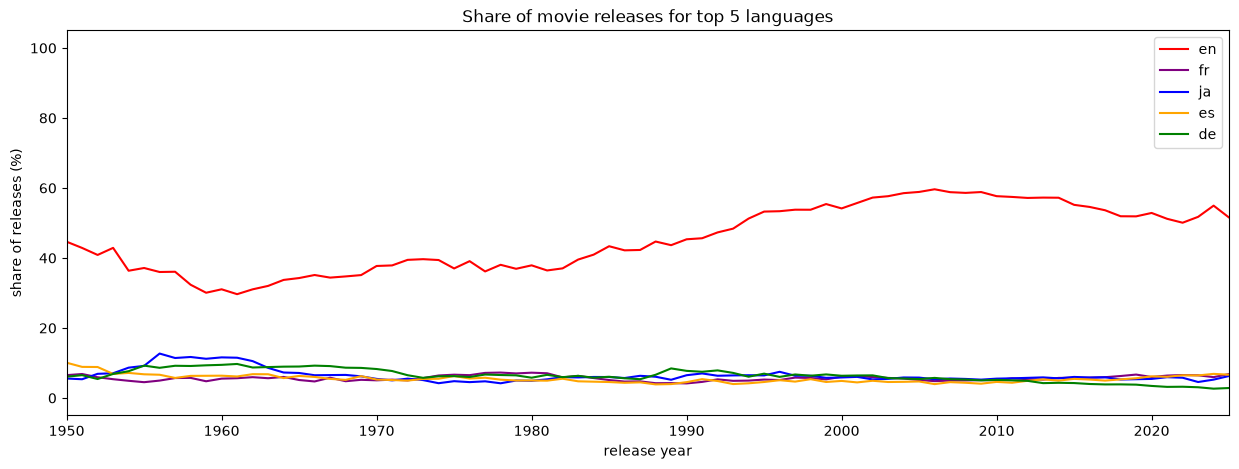

In [164]:
language_percentages = year_languages.div(release_years_count, axis=0) * 100

plt.figure(figsize=(15, 5))
for language in language_order:
    plt.plot(language_percentages.index, language_percentages[language], label=language,color=language_colors.get(language, 'gray'))
plt.title('Share of movie releases for top 5 languages')
plt.xlabel('release year')
plt.ylabel('share of releases (%)')
plt.xlim(1950, 2025)
plt.legend()
plt.show()

## Release dates: top 5 languages

We look at release dates for the top 5 languages (English, French, Japanese, Spanish and German). In absolute numbers, English movies account for the largest share of releases, but theres a noticable increase of other language releases in the 2010s. When we look at percentages of released movies per year, we see a slight decline for English movies in the 1960s, an increase in the 1990s and another slight decrease in the 2020s. Interestingly, percentage wise Japanese movies had an increase in the late 1950s to early 1960s.